In [1]:
from load_basics import *
from nbodykit.source.catalog import BigFileCatalog
from nbodykit.lab import ArrayCatalog, FFTPower

In [2]:
alist = np.linspace(0.05, 1, 40)
# alist = np.floor(alist * 10000) / 10000
zlist = 1/alist - 1
print(zlist)

[19.         12.44827586  9.12987013  7.125       5.7826087   4.82089552
  4.09803922  3.53488372  3.08376963  2.71428571  2.40611354  2.14516129
  1.92134831  1.72727273  1.55737705  1.40740741  1.27405248  1.15469613
  1.04724409  0.95        0.86157518  0.78082192  0.70678337  0.63865546
  0.57575758  0.51750973  0.46341463  0.41304348  0.36602452  0.3220339
  0.28078818  0.24203822  0.20556414  0.17117117  0.13868613  0.10795455
  0.07883817  0.05121294  0.02496715  0.        ]


In [ ]:
oroot = "/home/nianyic/scratch1/FMsims/L400_n128_s40"
Nmesh = 128
Lbox = 400

In [21]:
def gen_mesh(irun, flist, snap):
    odir = f"{oroot}/s-{irun:04d}"
    asnap = alist[snap]
    sdir = flist[snap]

    bf = BigFile(sdir)
    pos = bf["1/Position"][:]
    vel = bf["1/Velocity"][:]
    cat = ArrayCatalog({'Position' : pos, 'Velocity' : vel}, BoxSize=[Lbox, Lbox, Lbox])
    mesh = cat.to_mesh(resampler='cic',Nmesh=Nmesh,position='Position')
    return mesh

def downsize(one_plus_delta, factor):
    """
    Downsize the mesh by a factor of `factor`.
    """
    if factor == 1:
        return one_plus_delta
    elif factor < 1:
        raise ValueError("Downsize factor must be >= 1")
    
    new_shape = (one_plus_delta.shape[0] // factor, 
                 one_plus_delta.shape[1] // factor, 
                 one_plus_delta.shape[2] // factor)
    
    downsampled = one_plus_delta.reshape(new_shape[0], factor, \
        new_shape[1], factor, new_shape[2], factor).mean(axis=(1,3,5))
    return downsampled

def plot_density(ax, one_plus_delta, label):
    ax.imshow(one_plus_delta[:,:,30],vmax=5,vmin=0.005)
    ax.set_title(label)
    ax.set_xlabel('x [Mpc/h]')
    ax.set_ylabel('y [Mpc/h]')

def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk


In [22]:
irun = 2
odir = f"{oroot}/s-{irun:04d}"
print(f"Output directory: {odir}")
flist = sorted(glob.glob(f"{odir}/fastpm_*"))
print(flist)

Output directory: /home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002
['/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.0500', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.0744', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.0987', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.1231', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.1474', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.1718', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.1962', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.2205', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.2449', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.2693', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.2936', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.3180', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s-0002/fastpm_0.3423', '/home/nianyic/scratch1/FMsims/L400_n128_s40/s

In [29]:
irun = 3
odir = f"{oroot}/s-{irun:04d}"

flist = sorted(glob.glob(f"{odir}/fastpm_*"))


meshlist = []
one_plus_delta_list = []
for i, snap in enumerate([0, 5, 18, 39]):
    mesh = gen_mesh(irun=irun, flist=flist, snap=snap)
    one_plus_delta = mesh.paint(mode='real').value
    one_plus_delta = downsize(one_plus_delta, 2)
    meshlist.append(mesh)
    one_plus_delta_list.append(one_plus_delta)

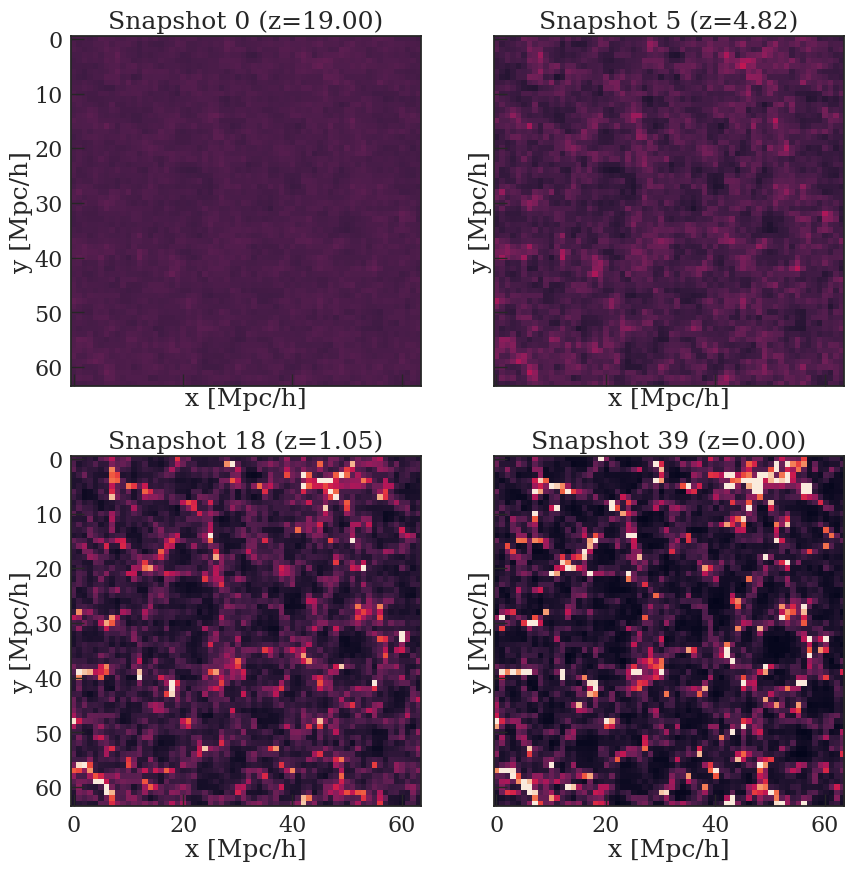

In [30]:

fig, ax = plt.subplots(figsize=(10,10),ncols=2,nrows=2, sharex=True, sharey=True)
ax = ax.flatten()
for i, snap in enumerate([0, 5, 18, 39]):
    plot_density(ax[i], one_plus_delta_list[i], f"Snapshot {snap} (z={zlist[snap]:.2f})")


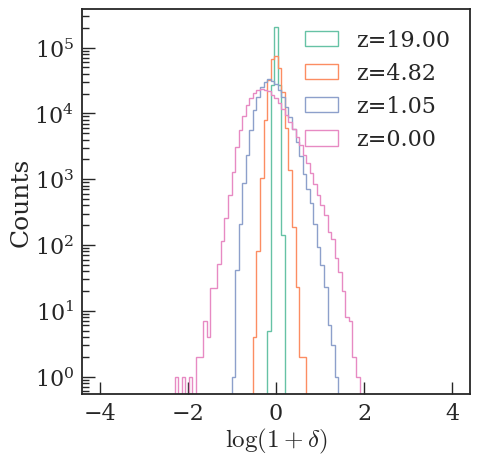

In [26]:
fig, ax = plt.subplots(1,1, figsize=(5, 5))
bins = np.linspace(-4, 4, 100)
for i, snap in enumerate([0, 5, 18, 39]):
    # one_plus_delta = meshlist[i].paint(mode='real')
    ax.hist(np.log10(one_plus_delta_list[i].flatten()), bins=bins, histtype='step', label=f"z={zlist[snap]:.2f}")
    ax.set(xlabel=r"$\log(1+\delta)$", ylabel='Counts', yscale='log')
ax.legend()
plt.show()

    

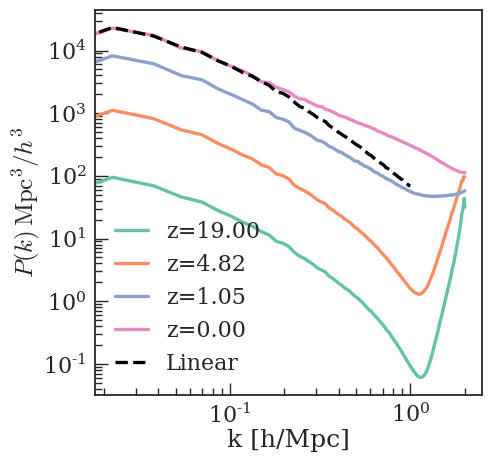

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
pfilelist = sorted(glob.glob(f"{odir}/powerspec_*.*.txt"))
for snap in [0, 5, 18, 39]:
    pfile = pfilelist[snap]
    k, p, n = np.loadtxt(pfile, unpack=True, skiprows=1)
    delta2 = p * k * k * k / (2 * np.pi * np.pi)
    # ax.plot(k, delta2, label=f"z={zlist[snap]:.2f}")
    ax.plot(k, p, label=f"z={zlist[snap]:.2f}")


k0, p0, n0 = np.loadtxt(f"{odir}/powerspec_linear.txt", unpack=True, skiprows=1)
ax.plot(k0, p0, label="Linear", linestyle='--', color='black')
ax.set(xlabel='k [h/Mpc]', ylabel=r'$P(k) \,\mathrm{Mpc}^3/h^3$', xscale='log', yscale='log')
ax.legend()
plt.show()



Text(0.5, 1.0, 'SR')

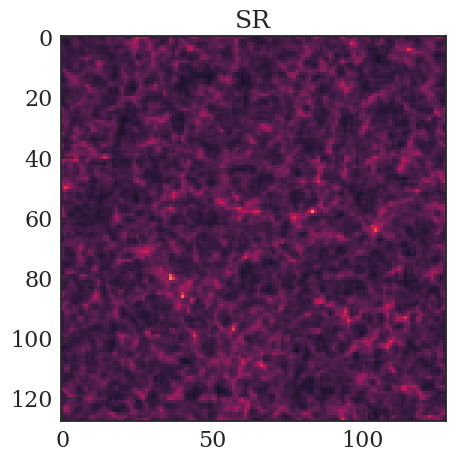

In [15]:
fig,ax = plt.subplots(figsize=(5,5),ncols=1,nrows=1)
ax.imshow(one_plus_delta.value[:,:,100],vmax=5,vmin=0.005)
ax.set_title('SR')

In [ ]:
f, ax = plt.subplots(2, 1, figsize=(6,5),gridspec_kw={'height_ratios': [3,1]}, sharex=True)
plt.subplots_adjust(hspace=0.0)
# plt.subplots_adjust(left=0.07, right=0.99, top=0.92, bottom=0.14)
ax[0].plot(k0,Pk,label='SR')
ax[0].plot(k0_hr,Pk_hr,label='HR')
ax[0].set(xscale='log',yscale='log',ylabel=r"$P(k)$ [$h^{-3}\mathrm{Mpc}^3$]")
ax[1].plot(k0,(Pk/Pk_hr))
ax[1].set(xscale='log',xlabel=r"$k$ [$h \ \mathrm{Mpc}^{-1}$]",ylim=[0.7,1.3])
ax[0].legend()
plt.show()
# plt.xlim(0.01, 10)